# Lecture 4 pre-work: Can a computer read an IR spectrum?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Edinburgh-Chemistry-Teaching/AdvancedPhysicalChemistry/blob/main/L4_classification/L4_prework_IR_classification.ipynb)

<a rel="license" href="https://creativecommons.org/licenses/by-sa/4.0/"><img alt="Creative Commons Licence" style="border-width:0" src="https://licensebuttons.net/l/by-sa/4.0/88x31.png" title='This work is licensed under a Creative Commons Attribution-ShareAlike 4.0 International License.' align="right"/></a>

Author: Dr Antonia Mey
Email: antonia.mey@ed.ac.uk

© Antonia Mey, University of Edinburgh, 2026. Text CC BY-SA 4.0; code cells MIT, see `LICENSE` and `LICENSE-CODE` in the repository.

**Before the lecture on Monday 16 November:** 
1. Watch the video
2. Work through Sections 0–5 of this notebook,
3. Do the short quiz on Learn.
   
**Expected duration**: about 40 minutes for the Notebook and 10 minutes for the video.   
**Additional material**: Sections 6 and 7 are optional practice for after the lecture.


### Learning objectives
By the end of this notebook, you should be able to
* Load a set of IR spectra and their labels with `pandas` and plot them.
* Split data into a training set and a test set, and explain why we need both.
* Train a decision tree and a random forest classifier with `scikit-learn`.
* Build a confusion matrix yourself and compute accuracy, precision and recall from it.

After the lecture (optional Sections 6 and 7), you should also be able to
* Explain why accuracy can be misleading when one class is rare.
* Use cross-validation to see how much a score depends on the train/test split.

### Table of Contents

0. [Refresher: loading and plotting spectra](#0-refresher)
1. [Features and labels](#1-features-and-labels)
2. [Training and test data](#2-training-and-test-data)
3. [A first classifier: the decision tree](#3-decision-tree)
4. [A random forest and the confusion matrix](#4-random-forest)
5. [Key points and questions for the lecture](#5-key-points)

**After the lecture (optional)**

6. [A harder problem: finding nitriles](#6-nitriles)
7. [Cross-validation](#7-cross-validation)

### The data

The spectra come from the [Chemotion Repository](https://www.chemotion-repository.net) collection *FT-IR spectroscopy data (Chemotion IR)*, [DOI: 10.22000/OGoEQGlsZGElrgst](https://doi.org/10.22000/OGoEQGlsZGElrgst). 

The spectra have been converted to absorbance on a common wavenumber grid (400–3996 cm⁻¹ in steps of 4 cm⁻¹), each spectrum has been scaled to lie between 0 and 1, and the functional groups in each molecule have been labelled from its structure.

### How to open this notebook

* **Noteable (recommended):** open it from the Lecture 4 page on Learn. Everything you need is already installed.
* **Google Colab (backup):** click the *Open in Colab* button at the top. You need a Google account. Save a copy to your Drive (*File → Save a copy in Drive*) or your answers will be lost.
* **Your own computer:** download or clone the repository and keep the folder structure, so that the notebook finds `../data/chemotion_ir_processed.csv`. You need `numpy`, `pandas`, `matplotlib` and `scikit-learn` (see `requirements.txt`).

The data are loaded in the *Import libraries* cell below: from the local `data/` folder if it is there, otherwise downloaded from GitHub (about 13 MB).

**<span style="color:black">Jupyter Cheat Sheet</span>**
- To run the currently highlighted cell and move focus to the next cell, hold <kbd>&#x21E7; Shift</kbd> and press <kbd>&#x23ce; Enter</kbd>;
- To get help for a specific function, place the cursor within the function's brackets, hold <kbd>&#x21E7; Shift</kbd>, and press <kbd>&#x21E5; Tab</kbd>;
- Cells marked `# FIXME` are for you to complete.

# Import libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score

# The data file lives in the data/ folder of the course repository.
# If it is not found locally (e.g. on Colab), it is downloaded from GitHub.
DATA_URL = "https://raw.githubusercontent.com/Edinburgh-Chemistry-Teaching/AdvancedPhysicalChemistry/main/data/chemotion_ir_processed.csv"

try:
    df = pd.read_csv("../data/chemotion_ir_processed.csv")
except FileNotFoundError:
    df = pd.read_csv(DATA_URL)

# 0. Refresher: loading and plotting spectra <a id="0-refresher"></a>

Each row of the table `df` is one IR spectrum. The first columns describe the molecule, then there is one column per functional group (1 = present, 0 = absent), and then one column per wavenumber containing the absorbance.

In [5]:
print(df.shape)
df.iloc[:5, :20]

(2064, 918)


,sample_id,smiles,instrument,carbonyl,ketone,aldehyde,ester,carboxylic_acid,amide,alcohol_phenol,amine_NH,nitrile,alkyne,alkene,aromatic,nitro,sulfonyl,halide,400,404
0,45039,CCOC(=O)c1ccc(cc1)/C/1=C/2\C=CC(=N2)/C(=c\2/cc...,Bruker ALPHA-T,1,0,0,1,0,0,0,0,0,1,1,1,0,0,0,0.0814,0.0512
1,45043,CCOC(=O)c1ccc(cc1)/C/1=C/2\C=CC(=N2)/C(=c\2/cc...,Bruker ALPHA-T,1,0,0,1,0,0,0,0,0,0,1,1,0,0,0,0.0575,0.0213
2,47142,CC(N(C(=O)Nc1cc2ccc1CCc1ccc(CC2)cc1)C(C)C)C,"Bruker, model IFS 88",1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0.0793,0.0728
3,45099,O=C1OC(N=C1Cc1c[nH]c2c1cccc2)C(F)(F)F,Bruker Alpha,1,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0.1304,0.1408
4,45100,Nc1ccc(cc1)c1cc2ccc1CCc1ccc(CC2)cc1,Bruker IFS88,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0.4068,0.4277


In [6]:
# The absorbance columns are the ones whose name is a number
wavenumber_columns = df.loc[:, "400":"3996"].columns
wavenumbers = np.array(wavenumber_columns, dtype=float)

group_columns = ["carbonyl", "ketone", "aldehyde", "ester", "carboxylic_acid", "amide",
                 "alcohol_phenol", "amine_NH", "nitrile", "alkyne", "alkene",
                 "aromatic", "nitro", "sulfonyl", "halide"]

print(f"{len(wavenumbers)} wavenumbers from {wavenumbers.min():.0f} to {wavenumbers.max():.0f} cm-1")

900 wavenumbers from 400 to 3996 cm-1


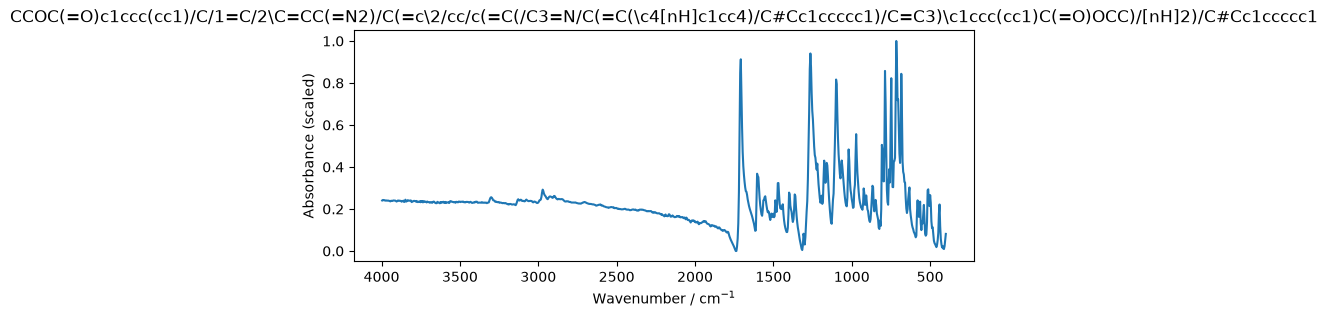

In [7]:
# Plot the first spectrum. IR spectra are usually drawn with wavenumber decreasing to the right.
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(wavenumbers, df.loc[0, wavenumber_columns])
ax.invert_xaxis()
ax.set_xlabel("Wavenumber / cm$^{-1}$")
ax.set_ylabel("Absorbance (scaled)")
ax.set_title(df.loc[0, "smiles"])
plt.show()

## Tasks 0 <a id="tasks-0"></a>

1. How many spectra contain a carbonyl group, and how many contain a nitrile? (Hint: the label columns contain 0s and 1s, so you can `sum()` them.)
2. An **average spectrum** is made by taking, at each wavenumber, the mean absorbance over a group of spectra. Compute the average spectrum of all molecules *with* a carbonyl group and the average spectrum of all molecules *without* one, and plot both on the same axes.
   * Where do the two curves differ most? Is that where you expect a C=O stretch?
   * Why is the carbonyl band in the average spectrum lower and broader than in a single spectrum?

   (Hint: `df.loc[df["carbonyl"] == 1, wavenumber_columns]` selects the absorbances of all spectra with a carbonyl group; `.mean()` then averages each column, i.e. each wavenumber.)

In [ ]:
# 1. Count carbonyls and nitriles
# FIXME

In [ ]:
# 2. Average spectrum with and without a carbonyl group
# FIXME

*Your answers to question 2 here.*

# 1. Features and labels <a id="1-features-and-labels"></a>

In machine learning language:
* the **features** $X$ are what the model sees: here the 900 absorbance values of each spectrum;
* the **labels** $y$ are what we want it to predict: here whether the molecule contains a given functional group.

This is a **classification** problem: the answer is a category (yes/no), not a number. Compare this with the fitting you did in Data-Driven Chemistry, where you predicted a number (a **regression** problem).

We start with the carbonyl group.

In [8]:
X = df[wavenumber_columns].values   # shape: (number of spectra, 900)
y = df["carbonyl"].values           # shape: (number of spectra,)
print(X.shape, y.shape)

(2064, 900) (2064,)


# 2. Training and test data <a id="2-training-and-test-data"></a>

If we judged a model on the same spectra it learned from, we would only find out how well it *remembers*, not how well it *predicts*. So we hide part of the data (the **test set**), train on the rest (the **training set**), and only look at the test set at the end.

Some molecules were measured more than once. We make sure that all spectra of the same molecule end up on the same side of the split, by grouping on the SMILES string. 

In [9]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=df["smiles"]))

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
print(f"training spectra: {len(y_train)}, test spectra: {len(y_test)}")

training spectra: 1542, test spectra: 522


# 3. A first classifier: the decision tree <a id="3-decision-tree"></a>

A decision tree asks a series of yes/no questions about the features, such as *"is the absorbance at 1700 cm$^{-1}$ greater than 0.4?"*, and follows the branches until it reaches an answer. It is a flowchart that the computer builds from the training data. 

Every model in `scikit-learn` is used in the same way:
1. create the model,
2. `fit` it to the training data,
3. `predict` on new data.

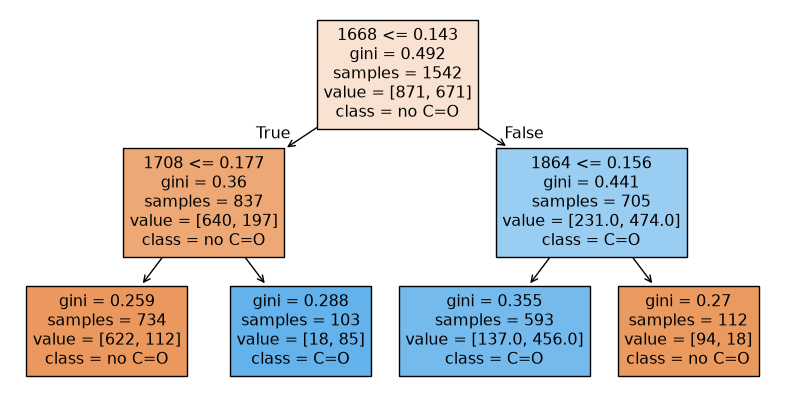

In [10]:
# Creates the model
tree = DecisionTreeClassifier(max_depth=2, random_state=0)
# Fits the model
tree.fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(10, 5))
plot_tree(tree, feature_names=list(wavenumber_columns),
          class_names=["no C=O", "C=O"], filled=True, ax=ax)
plt.show()

**How to read the tree.** Each box is one question. Apart from the question itself, it lists:

* the question at the top, e.g. `1700 <= 0.25` means "is the absorbance at 1700 cm$^{-1}$ at most 0.25?". If the answer is **yes (True)**, follow the **left** arrow; if **no (False)**, the **right** one. The boxes at the bottom (the *leaves*) ask no question: they give the answer.

## Tasks 1 <a id="tasks-1"></a>

1. Which wavenumbers has the tree chosen to ask about? Do they make chemical sense?
2. Use `tree.predict(X_test)` to predict the labels of the test set, and compute the fraction of test spectra that are classified correctly.

In [ ]:
# 2. Predict the test set and compute the fraction correct
# FIXME

# 4. A random forest and the confusion matrix <a id="4-random-forest"></a>

A single tree is easy to read, but it is sensitive to exactly which spectra it was trained on. A **random forest** trains many trees, each on a random resample of the training data and a random subset of the features, and lets them vote. 

In [ ]:
forest = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1)
forest.fit(X_train, y_train)
y_pred = forest.predict(X_test)

### The confusion matrix

For a yes/no classifier, every test spectrum falls into one of four boxes:

| | predicted C=O | predicted no C=O |
|---|---|---|
| **C=O present** | true positive (TP) | false negative (FN) |
| **C=O absent** | false positive (FP) | true negative (TN) |

From these we define:

$$\text{accuracy} = \frac{TP + TN}{TP + TN + FP + FN} \qquad
\text{precision} = \frac{TP}{TP + FP} \qquad
\text{recall} = \frac{TP}{TP + FN}$$

* **Precision:** when the model says "carbonyl", how often is it right?
* **Recall:** of all the carbonyls that are really there, how many does the model find?

You met false positives and false negatives in Data-Driven Chemistry as Type I and Type II errors in hypothesis testing.

## Tasks 2 <a id="tasks-2"></a>

1. Count TP, FP, FN and TN yourself by comparing `y_test` and `y_pred`. (Hint: `(y_test == 1) & (y_pred == 1)` is `True` for every true positive.)
2. Compute accuracy, precision and recall from your counts.
3. Check your answers with `confusion_matrix`, `accuracy_score`, `precision_score` and `recall_score` from `sklearn.metrics`. Use `confusion_matrix(y_test, y_pred, labels=[1, 0])` so that the matrix has the same layout as the table above (`[[TP, FN], [FP, TN]]`).
4. Plot the confusion matrix with the cell below and check it against your counts.

In [ ]:
# 1. and 2. Confusion matrix and metrics by hand
# FIXME

In [ ]:
# 3. Check with scikit-learn
# FIXME

In [ ]:
# Plot the confusion matrix (same layout as the table above: C=O first)
fig, ax = plt.subplots(figsize=(4, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=[1, 0],
                                        display_labels=["C=O", "no C=O"],
                                        cmap="Blues", colorbar=False, ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
plt.show()

**Before the lecture:** the forest uses all 900 wavenumbers. Write down which wavenumber region(s) you expect it to rely on most for spotting a carbonyl. We will check in the lecture.

**This is the end of the pre-work.** Read the key points in Section 5, then do the quiz on Learn.

# 5. Key points and questions for the lecture <a id="5-key-points"></a>

* Classification predicts a category. In `scikit-learn`  a classification model is used with `fit` and `predict`.
* A model must be judged on data it has not seen namely the **test set**.
* A decision tree is a learned flowchart, while a random forest combines the vote of many trees.  
* The **confusion matrix** (TP, FP, FN, TN) gives us the data for any classification metric: accuracy, precision and recall.

**Bring to the lecture:**
1. Your confusion matrix and your accuracy, precision and recall for the carbonyl classifier. We will use them in class.
2. Your prediction of which wavenumbers matter most for carbonyls.

**Now do the short quiz on Learn.**

---

# After the lecture (optional)

The next two sections pick up two questions from the lecture: what happens when the functional group you are looking for is **rare**, and how much a score depends on the particular train/test split.

# 6. A harder problem: finding nitriles <a id="6-nitriles"></a>

The function below repeats everything from Sections 2 and 4 for any functional group in the table.

In [ ]:
def train_and_test(group):
    """Train a random forest to detect `group`; return the true and predicted test labels."""
    y = df[group].values
    train_idx, test_idx = next(splitter.split(X, y, groups=df["smiles"]))
    model = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1)
    model.fit(X[train_idx], y[train_idx])
    return y[test_idx], model.predict(X[test_idx])

y_test_cn, y_pred_cn = train_and_test("nitrile")

## Tasks 3 <a id="tasks-3"></a>

1. Compute the accuracy, precision and recall of the nitrile classifier.
2. A lazy "classifier" that always answers *"no nitrile"* needs no training at all. What accuracy would it get on this test set? Compare with your model.
3. In one or two sentences: is the nitrile classifier useful? Which number tells you most?

In [ ]:
# 1. Metrics for the nitrile classifier
# FIXME

In [ ]:
# 2. Accuracy of always answering "no nitrile"
# FIXME

*Your answer to question 3 here.*

# 7. Cross-validation <a id="7-cross-validation"></a>

Our test set is one random choice of 25% of the molecules. With a different choice, the numbers would change. **Cross-validation** splits the data into $k$ parts (*folds*), uses each part once as the test set, and reports all $k$ scores.

Run the cell below. It may take up to a minute.

In [ ]:
y_cn = df["nitrile"].values
scores = cross_val_score(RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1),
                         X, y_cn, groups=df["smiles"], cv=GroupKFold(n_splits=5), scoring="recall")
print("nitrile recall in each fold:", np.round(scores, 2))
print(f"mean = {scores.mean():.2f}, standard deviation = {scores.std():.2f}")

## Tasks 4 <a id="tasks-4"></a>

1. How much does the recall vary between folds? Why might it vary so much for nitriles in particular? (Hint: how many nitriles are in each test fold?)
2. **Optional:** use `train_and_test` to try another functional group, such as `"alcohol_phenol"` or `"ester"`. Which groups are easy, and which are hard? Can you explain why from the spectra?

In [ ]:
# Optional: try another functional group
# FIXME